In [61]:
import pandas as pd

players = pd.read_csv("../data/stats_player_week_2026.csv")
players.head()

,player_id,player_name,player_display_name,position,position_group,headshot_url,season,week,season_type,game_id,...,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards,fantasy_points,fantasy_points_ppr
0,00-0023459,A.Rodgers,Aaron Rodgers,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_ATL_PIT,...,0,0,0,0,0,0,0,0,12.54,12.54
1,00-0025565,N.Folk,Nick Folk,K,SPEC,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_ATL_PIT,...,0,0,0,0,0,0,0,0,0.00,0.00
2,00-0026190,C.Campbell,Calais Campbell,DE,DL,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_BAL_IND,...,0,0,0,0,0,0,0,0,0.00,0.00
3,00-0026498,M.Stafford,Matthew Stafford,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_SF_LA,...,0,0,0,0,0,0,0,0,4.10,4.10
4,00-0027969,C.Heyward,Cameron Heyward,DE,DL,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_ATL_PIT,...,0,0,0,0,0,0,0,0,0.00,0.00


In [62]:
# csv_file.loc[which rows, which columns]

receivers = players.loc[
    players["position"] == "WR",
    ["player_display_name", "week", "targets", "receptions", "receiving_yards"],
]

receivers.head()

,player_display_name,week,targets,receptions,receiving_yards
12,Keenan Allen,1,6,6,32
23,Davante Adams,1,6,3,26
24,Mike Evans,1,7,6,49
30,Stefon Diggs,1,9,4,55
43,Chris Moore,1,2,1,53


In [63]:
top_games = receivers.sort_values(by="receiving_yards", ascending=False)

top_games.head(10)

,player_display_name,week,targets,receptions,receiving_yards
1148,Davante Adams,2,10,8,195
2695,Drake London,3,10,9,194
4175,Tetairoa McMillan,4,16,14,192
3658,CeeDee Lamb,4,21,17,189
484,Chris Olave,1,13,10,182
6116,Malik Nabers,6,15,12,165
3669,Tee Higgins,4,16,11,157
1706,Jaxon Smith-Njigba,2,11,9,155
1454,CeeDee Lamb,2,9,8,153
689,Zay Flowers,1,6,5,150


In [64]:
receiver_totals = receivers.groupby(
    "player_display_name",
    as_index=False,
)[["targets", "receptions", "receiving_yards"]].sum()

receiver_totals.sort_values(
    by="receiving_yards",
    ascending=False,
).head(10)

,player_display_name,targets,receptions,receiving_yards
97,Jaxon Smith-Njigba,66,49,717
32,Chris Olave,61,43,580
25,CeeDee Lamb,69,48,577
61,Drake London,46,31,550
33,Christian Watson,48,29,538
152,Matthew Golden,57,30,501
146,Malik Nabers,61,41,494
46,Davante Adams,49,30,480
189,Tetairoa McMillan,48,32,471
210,Zay Flowers,42,32,471


In [65]:
receiver_totals["catch_percentage"] = (
    receiver_totals["receptions"] / receiver_totals["targets"] * 100
)

receiver_totals.head()

,player_display_name,targets,receptions,receiving_yards,catch_percentage
0,A.J. Brown,14,6,53,42.857143
1,Adonai Mitchell,15,9,123,60.000000
2,Alec Pierce,7,5,72,71.428571
3,Alex Bachman,0,0,0,NaN
4,Amon-Ra St. Brown,57,37,372,64.912281


In [66]:
qualified_receivers = receiver_totals.loc[receiver_totals["targets"] >= 20]

qualified_receivers.sort_values(
    by="catch_percentage",
    ascending=False,
).head(10)

,player_display_name,targets,receptions,receiving_yards,catch_percentage
118,Kalif Raymond,29,26,244,89.655172
101,Jaylin Noel,21,17,334,80.952381
50,Deebo Samuel Sr.,20,16,206,80.000000
30,Chris Godwin Jr.,29,23,216,79.310345
113,Justin Jefferson,24,19,258,79.166667
125,Keon Coleman,24,19,283,79.166667
210,Zay Flowers,42,32,471,76.190476
70,Germie Bernard,32,24,227,75.000000
140,Mack Hollins,20,15,209,75.000000
97,Jaxon Smith-Njigba,66,49,717,74.242424


In [67]:
yards_per_reception = receiver_totals["yards_per_reception"] = (
    receiver_totals["receiving_yards"] / receiver_totals["receptions"]
)

yards_per_target = receiver_totals["yards_per_target"] = (
    receiver_totals["receiving_yards"] / receiver_totals["targets"]
)


In [68]:
qualified_receivers = receiver_totals.loc[
    receiver_totals["targets"] >= 20
]

qualified_receivers.sort_values(
    by="yards_per_target",
    ascending=False,
).head(10)

,player_display_name,targets,receptions,receiving_yards,catch_percentage,yards_per_reception,yards_per_target
101,Jaylin Noel,21,17,334,80.952381,19.647059,15.904762
61,Drake London,46,31,550,67.391304,17.741935,11.956522
125,Keon Coleman,24,19,283,79.166667,14.894737,11.791667
210,Zay Flowers,42,32,471,76.190476,14.718750,11.214286
33,Christian Watson,48,29,538,60.416667,18.551724,11.208333
175,Romeo Doubs,24,14,261,58.333333,18.642857,10.875000
97,Jaxon Smith-Njigba,66,49,717,74.242424,14.632653,10.863636
155,Mike Evans,39,27,420,69.230769,15.555556,10.769231
160,Nico Collins,30,22,323,73.333333,14.681818,10.766667
113,Justin Jefferson,24,19,258,79.166667,13.578947,10.750000


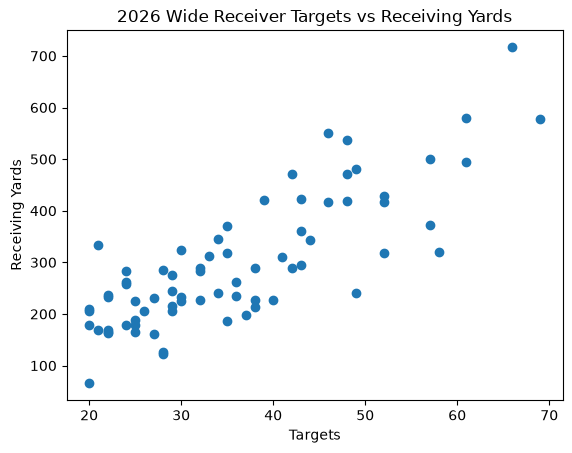

In [69]:
import matplotlib.pyplot as plt

plt.scatter(qualified_receivers["targets"], qualified_receivers["receiving_yards"])
plt.xlabel("Targets")
plt.ylabel("Receiving Yards")
plt.title("2026 Wide Receiver Targets vs Receiving Yards")
plt.show()

In [70]:
receiver_per_game = receivers.groupby(
    "player_display_name",
    as_index=False,
).agg(
    games_recorded=("week", "size"),
    total_targets=("targets", "sum"),
    total_yards=("receiving_yards", "sum"),
)

# .agg() allows you to rename the columns in the resulting DataFrame.
# The syntax is a dictionary where the keys are the new column names,
# The values are tuples containing the original column name and the aggregation function to apply.

# "size" counts the number of rows in each group
# "sum" adds up the values in the specified column for each group.

receiver_per_game["targets_per_game"] = (
    receiver_per_game["total_targets"] / receiver_per_game["games_recorded"]
)

receiver_per_game["yards_per_game"] = (
    receiver_per_game["total_yards"] / receiver_per_game["games_recorded"]
)

receiver_per_game.head()

,player_display_name,games_recorded,total_targets,total_yards,targets_per_game,yards_per_game
0,A.J. Brown,2,14,53,7.0,26.5
1,Adonai Mitchell,2,15,123,7.5,61.5
2,Alec Pierce,2,7,72,3.5,36.0
3,Alex Bachman,3,0,0,0.0,0.0
4,Amon-Ra St. Brown,5,57,372,11.4,74.4


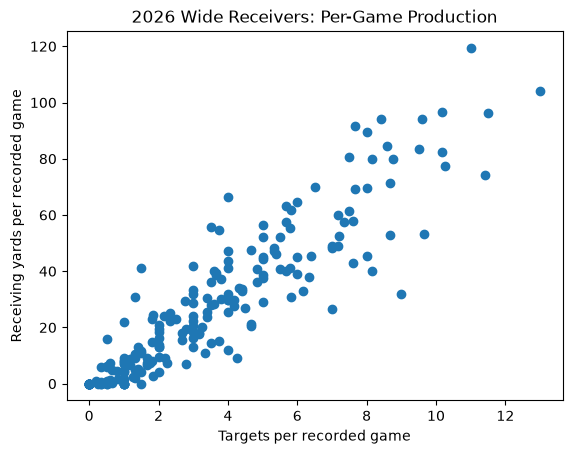

In [71]:
plt.scatter(
    receiver_per_game["targets_per_game"],
    receiver_per_game["yards_per_game"],
)
plt.xlabel("Targets per recorded game")
plt.ylabel("Receiving yards per recorded game")
plt.title("2026 Wide Receivers: Per-Game Production")
plt.show()

## Takeaway

Receiving yards generally increased with targets in this dataset.
The pattern appeared in both totals and per-game averages.
These results describe an ongoing season and do not prove causation.